In [3]:
import numpy as np
from random_mps import (produce_a_random_mps,
)
import timeit

In [6]:
# Pauli-Z matrix
Z = np.array([[1, 0], [0, -1]])
I = np.eye(2)

def build_transfer_matrix(A, Op):
    """
    Builds the transfer matrix for a single site.
    A: tensor of shape (d, D_left, D_right)
    O: operator of shape (d, d)
    """
    d, Dl, Dr = A.shape
    T = np.zeros((Dl * Dl, Dr * Dr), dtype=np.complex128)
    for s in range(d):
        for sp in range(d):
            A_s = A[s]             # shape (Dl, Dr)
            A_sp_conj = np.conj(A[sp])  # shape (Dl, Dr)
            coeff = Op[sp, s]
            if coeff != 0: 
                kron = np.kron(A_s, A_sp_conj)  # Kronecker product of two arrays. shape (Dl*Dl, Dr*Dr)
                T += coeff * kron
    return T  # shape (Dl^2, Dr^2)

def compute_C_zz(list_A, i, j):
    """
    Compute C^{zz}(i,j) = <psi|Z_i Z_j|psi>
    list_A: list of tensors (d, D_left, D_right)
    """
    L = len(list_A)
    assert 0 <= i < j < L

    env = np.array([[1.0]], dtype=np.complex128)  # scalar identity

    for n in range(0, i):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    T = build_transfer_matrix(list_A[i], Z)
    env = env @ T

    for n in range(i + 1, j):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    T = build_transfer_matrix(list_A[j], Z)
    env = env @ T

    for n in range(j + 1, L):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    return np.trace(env)

def generate_random_MPS(L, D, d=2):
    """
    Generate a random MPS with physical dimension 2, L sites, and bond dimension D.
    Returns a list of tensors with shape (2, D_left, D_right)
    """
    list_M, _, _, _ = produce_a_random_mps(L, d)
    return list_M

def average_correlation_matrix(L, D, num_samples):
    """
    Compute averaged C^{zz}(i,j) matrix for all pairs (i, j)
    """
    corr_matrix = np.zeros((L, L))
    for _ in range(num_samples):
        list_M = generate_random_MPS(L, D)
        for i in range(L):
            for j in range(i + 1, L):
                c = compute_C_zz(list_M, i, j).real
                corr_matrix[i, j] += c
                corr_matrix[j, i] += c  # symmetric
    corr_matrix /= num_samples
    return corr_matrix

In [7]:
"""
Code based on the theory from "The density-matrix renormalization group in the age of 
the matrix product states" by Ulrich Schollwöck §4.2.1.
"""

def contract1(A, C, Op=None):
    """
    WRITE WHAT IT DOES.
    A: tensor of shape (d, D_left, D_right)
    C: mtrix of dimension (D_right, D_right)
    O: operator of shape (d, d)
    """
    
    d, Dl, Dr = A.shape
    new_C = np.zeros((Dr, Dr),  dtype=np.complex128)
    if Op is None:
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T  # shape (Dr, Dl)
            new_C += A_s_dagger @ C @ A[s] 
        return new_C
    else: # Apply the operator
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T  # shape (Dr, Dl)
            for sp in range(d):
                new_C +=  Op[s,sp] * A_s_dagger @ C @ A[sp]
        return new_C # shape (Dl, Dl)


def compute_C_zz2(list_A, i, j):
    """
    Compute C^{zz}(i,j) = <psi|Z_i Z_j|psi>
    list_A: list of tensors (d, D_left, D_right)
    """
    L = len(list_A)
    assert 0 <= i < j < L

    C = np.array([[1.0]], dtype=np.complex128)  # scalar identity

    for n in range(0, i):
        C = contract1(list_A[n], C, None)

    C = contract1(list_A[i], C, Z)

    for n in range(i + 1, j):
        C = contract1(list_A[n], C, None)

    C = contract1(list_A[j], C, Z)

    for n in range(j + 1, L):
        C = contract1(list_A[n], C, None)

    return C


def average_correlation_matrix2(L, D, num_samples):
    """
    Compute averaged C^{zz}(i,j) matrix for all pairs (i, j)
    """
    corr_matrix = np.zeros((L, L))
    for _ in range(num_samples):
        list_M = generate_random_MPS(L, D)
        for i in range(L):
            for j in range(i + 1, L):
                c = compute_C_zz2(list_M, i, j).real
                corr_matrix[i, j] += c
                corr_matrix[j, i] += c  # symmetric
    corr_matrix /= num_samples
    return corr_matrix

In [8]:
np.random.seed(3)
#  Example usage:
N = 8
D = 4
num_samples = 1
start = timeit.default_timer()
corr_mat = average_correlation_matrix2(N, D, num_samples)
stop = timeit.default_timer()
print(corr_mat)
print('Time: ', stop - start) 

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


[[ 0.00000000e+00 -1.02435775e-01 -5.84445693e-02  8.14737962e-02
  -1.20545109e-01  1.18452633e-01  3.40018614e-02  1.79258079e-02]
 [-1.02435775e-01  0.00000000e+00 -1.13132580e-01  6.74032112e-02
   1.92088928e-01  3.75669327e-02  1.12611018e-02 -1.99332521e-04]
 [-5.84445693e-02 -1.13132580e-01  0.00000000e+00 -2.04236016e-01
   6.54298927e-02  6.92815166e-02  1.50113494e-01 -3.94927651e-02]
 [ 8.14737962e-02  6.74032112e-02 -2.04236016e-01  0.00000000e+00
  -6.65371119e-02 -1.82364662e-01  9.33384657e-04  8.57372250e-02]
 [-1.20545109e-01  1.92088928e-01  6.54298927e-02 -6.65371119e-02
   0.00000000e+00  2.82958152e-02 -4.40681254e-02 -3.70543916e-02]
 [ 1.18452633e-01  3.75669327e-02  6.92815166e-02 -1.82364662e-01
   2.82958152e-02  0.00000000e+00 -1.11714691e-01  2.20449042e-01]
 [ 3.40018614e-02  1.12611018e-02  1.50113494e-01  9.33384657e-04
  -4.40681254e-02 -1.11714691e-01  0.00000000e+00 -2.42448184e-01]
 [ 1.79258079e-02 -1.99332521e-04 -3.94927651e-02  8.57372250e-02
  -

/tmp/ipykernel_1728563/2042637906.py:67: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corr_matrix[i, j] += c
/tmp/ipykernel_1728563/2042637906.py:68: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corr_matrix[j, i] += c  # symmetric


In [10]:
np.random.seed(3)#  Example usage:
N = 8
D = 4
num_samples = 1
start = timeit.default_timer()
corr_mat = average_correlation_matrix(N, D, num_samples)
stop = timeit.default_timer()
print(corr_mat)
print('Time: ', stop - start)  

[[ 0.00000000e+00 -1.02435775e-01 -5.84445693e-02  8.14737962e-02
  -1.20545109e-01  1.18452633e-01  3.40018614e-02  1.79258079e-02]
 [-1.02435775e-01  0.00000000e+00 -1.13132580e-01  6.74032112e-02
   1.92088928e-01  3.75669327e-02  1.12611018e-02 -1.99332521e-04]
 [-5.84445693e-02 -1.13132580e-01  0.00000000e+00 -2.04236016e-01
   6.54298927e-02  6.92815166e-02  1.50113494e-01 -3.94927651e-02]
 [ 8.14737962e-02  6.74032112e-02 -2.04236016e-01  0.00000000e+00
  -6.65371119e-02 -1.82364662e-01  9.33384657e-04  8.57372250e-02]
 [-1.20545109e-01  1.92088928e-01  6.54298927e-02 -6.65371119e-02
   0.00000000e+00  2.82958152e-02 -4.40681254e-02 -3.70543916e-02]
 [ 1.18452633e-01  3.75669327e-02  6.92815166e-02 -1.82364662e-01
   2.82958152e-02  0.00000000e+00 -1.11714691e-01  2.20449042e-01]
 [ 3.40018614e-02  1.12611018e-02  1.50113494e-01  9.33384657e-04
  -4.40681254e-02 -1.11714691e-01  0.00000000e+00 -2.42448184e-01]
 [ 1.79258079e-02 -1.99332521e-04 -3.94927651e-02  8.57372250e-02
  -

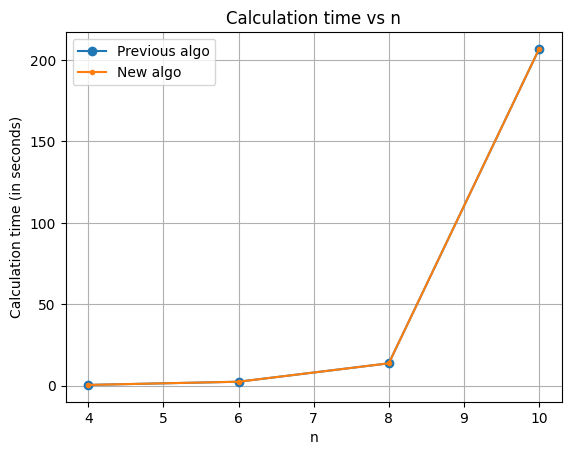

In [15]:
import matplotlib.pyplot as plt

n_list = np.array([4,6,8,10])
time_algoh = np.array([0.4824, 2.4443, 13.7511, 206.8611])
time_algos = np.array([0.4872, 2.5865, 13.6689, 205.2621])
plt.plot(n_list, time_algoh, marker='o', label="Previous algo")
plt.plot(n_list, time_algoh, marker='.', label="New algo")
plt.xlabel('n')
plt.ylabel('Calculation time (in seconds)')
plt.title('Calculation time vs n')
plt.grid(True)
plt.legend()
plt.show()

In [20]:
# # def build_transfer_matrix_einsum(A, Op):
# #     """
# #     Efficient transfer matrix using einsum.
# #     A: shape (d, Dl, Dr)
# #     Op: shape (d, d)
# #     Returns T: shape (Dl*Dl, Dr*Dr)
# #     """
# #     d, Dl, Dr = A.shape
# #     T = np.einsum('sp,slr,sLr->llLL', Op, A, np.conj(A))  # indices: s,p,l,r,L,R
# #     T = T.reshape(Dl * Dl, Dr * Dr)
# #     return T


# def build_transfer_matrix(A, Op):
#     """
#     Builds the transfer matrix for a single site.
#     A: tensor of shape (d, D_left, D_right)
#     O: operator of shape (d, d)
#     """
#     d, Dl, Dr = A.shape
#     T = np.zeros((Dl * Dl, Dr * Dr), dtype=np.complex128)
#     for s in range(d):
#         for sp in range(d):
#             A_s = A[s]             # shape (Dl, Dr)
#             A_sp_conj = np.conj(A[sp])  # shape (Dl, Dr)
#             coeff = Op[sp, s]
#             if coeff != 0: 
#                 kron = np.kron(A_s, A_sp_conj)  # Kronecker product of two arrays. shape (Dl*Dl, Dr*Dr)
#                 T += coeff * kron
#     return T  # shape (Dl^2, Dr^2)

# def compute_all_two_site_corrs(list_A, O1, O2=None, connected=False):
#     """
#     Computes <O1_i O2_j> (or connected version) for all i < j.
#     list_A: list of MPS tensors (d, Dl, Dr)
#     O1, O2: operators (default: O2 = O1)
#     """
#     if O2 is None:
#         O2 = O1

#     N = len(list_A)
#     d, Dl, Dr = list_A[0].shape
#     corr_matrix = np.zeros((N, N), dtype=np.float64)

#     # Identity operator
#     I = np.eye(d)

#     # Precompute transfer matrices
#     T_list = [build_transfer_matrix(A, I) for A in list_A]
#     T_op1_list = [build_transfer_matrix(A, O1) for A in list_A]
#     T_op2_list = [build_transfer_matrix(A, O2) for A in list_A]

#     # Precompute one-site expectations if connected version needed
#     one_site_vals = np.zeros(N)
#     if connected:
#         for i in range(N):
#             env = np.array([[1.0]], dtype=np.complex128)
#             for n in range(i):
#                 env = env @ T_list[n]
#             env = env @ T_op1_list[i]
#             for n in range(i + 1, N):
#                 env = env @ T_list[n]
#             one_site_vals[i] = np.trace(env).real

#     # Left-to-right sweep
#     L = np.array([[1.0]], dtype=np.complex128)
#     for i in range(N):
#         L_i = L @ T_op1_list[i]
#         R = np.identity(L_i.shape[1], dtype=np.complex128)
#         for j in range(i + 1, N):
#             R = T_list[j - 1] @ R
#             Tij = T_op2_list[j]
#             full_env = L_i @ Tij @ R
#             val = np.trace(full_env).real
#             if connected:
#                 val -= one_site_vals[i] * one_site_vals[j]
#             corr_matrix[i, j] = val
#             corr_matrix[j, i] = val
#         if i < N - 1:
#             L = L @ T_list[i]
#     return corr_matrix

# def average_correlation_matrix3(L, D, num_samples):
#     """
#     Compute averaged C^{zz}(i,j) matrix for all pairs (i, j)
#     """
#     corr_matrix = np.zeros((L, L))
#     for _ in range(num_samples):
#         list_M = generate_random_MPS(L, D)
#         corr_matrix += compute_all_two_site_corrs(list_M, Z, O2=None, connected=False)
#     corr_matrix /= num_samples
#     return corr_matrix



In [21]:
# np.random.seed(3)#  Example usage:
# N = 4
# D = 4
# num_samples = 1
# start = timeit.default_timer()
# corr_mat = average_correlation_matrix3(N, D, num_samples)
# stop = timeit.default_timer()
# print(corr_mat)
# print('Time: ', stop - start)  

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 1 is different from 16)